100%|██████████| 10000/10000 [01:41<00:00, 98.67it/s] 


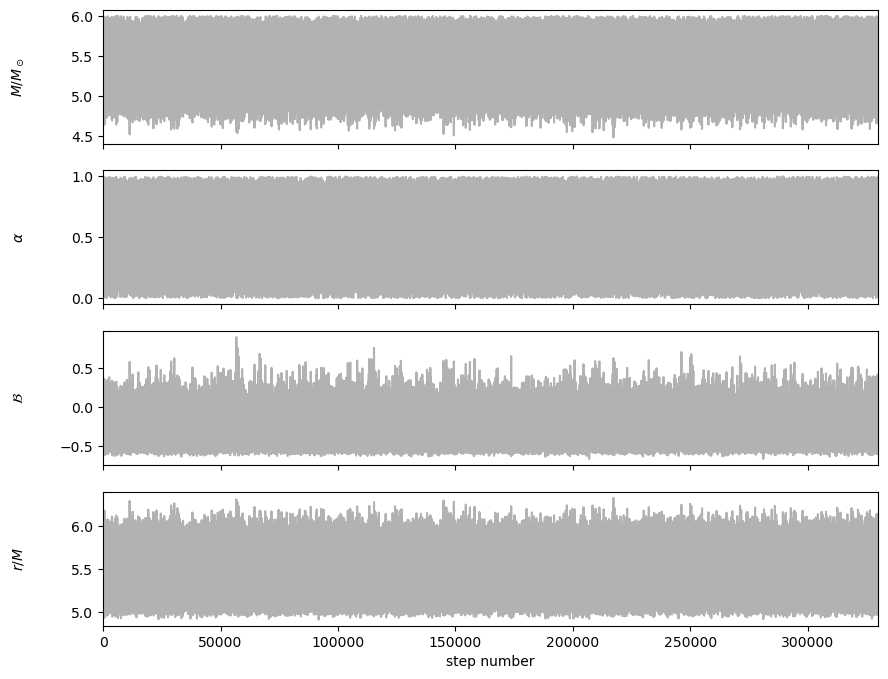

Removed no burn in


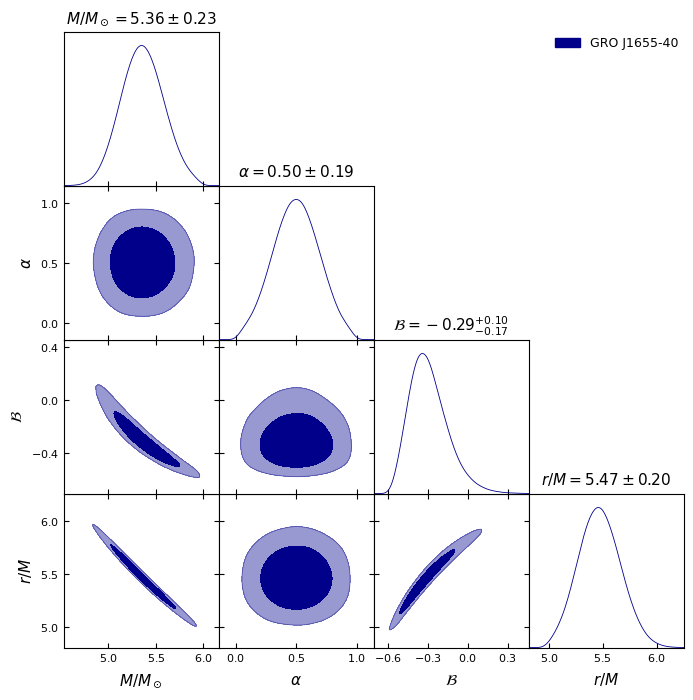

In [1]:
import numpy as np
import emcee
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# Define the Uppfreq function
def mysqrt(x): 
    return np.sqrt(x)

def Uppfreq(M, a, b, r):
    output=(32212.8*(mysqrt(((r**-4.)*((-0.49*(np.exp((-b))))+r)))))/M

    return output

# Define the Lowfreq function
def Lowfreq(M, a, b, r):
    aux0=(-0.9604*(np.exp((-2.*b))))+((4.41*((np.exp((-b)))*r))+((-6.+r)*(r**2)));
    output=((32212.8*(mysqrt(((r**-4.)*((-0.49*(np.exp((-b))))+r)))))/M)+((-32212.8*(mysqrt(((r**-6.)*aux0))))/M)
  
    return output
# Data in the given format
data = {
    "upper": [441],
    "upper_err": [2],
    "lower": [298],
    "lower_err": [4]
}

# Extracting the data from the dictionary
nu_up_obs = np.array(data["upper"])
sigma_up_obs = np.array(data["upper_err"])
nu_low_obs = np.array(data["lower"])
sigma_low_obs = np.array(data["lower_err"])

# Theoretical functions
def nu_up_th(params):
    M, a, b, r = params
    return Uppfreq(M, a, b, r)

def nu_low_th(params):
    M, a, b, r = params
    return Lowfreq(M, a, b, r)

# Define the log likelihood function
def log_likelihood(params):
    M, a, b, r = params

    nu_up_th_values = nu_up_th(params)
    nu_low_th_values = nu_low_th(params)

    logL_up = -0.5 * np.sum(((nu_up_obs - nu_up_th_values) / sigma_up_obs) ** 2)
    logL_low = -0.5 * np.sum(((nu_low_obs - nu_low_th_values) / sigma_low_obs) ** 2)

    return logL_up + logL_low

# Prior parameters
Theta_0 = [5.4, 0.5, -0.225, 5.39]  # Example mean values for the priors
sigma_i = [0.3, 0.2, 0.5, 0.33]  # Example standard deviations for the priors
Theta_low = [4.0, 0., -1.0, 1.0]
Theta_high = [6.0, 1.0, 1.0, 10.0]

# Define the log prior function
def log_prior(params):
    M, a, b, r = params
    if not (Theta_low[0] < M < Theta_high[0] and Theta_low[1] < a < Theta_high[1] and Theta_low[2] < b < Theta_high[2] and Theta_low[3] < r < Theta_high[3]):
        return -np.inf  # Out of bounds

    logP_M = -0.5 * ((M - Theta_0[0]) / sigma_i[0]) ** 2
    logP_a = -0.5 * ((a - Theta_0[1]) / sigma_i[1]) ** 2
    logP_b = -0.5 * ((b - Theta_0[2]) / sigma_i[2]) ** 2
    logP_r = -0.5 * ((r - Theta_0[3]) / sigma_i[3]) ** 2

    return logP_M + logP_a + logP_b + logP_r

# Define the log posterior function
def log_posterior(params):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params)

# Set up the MCMC sampler
ndim = 4  # Number of parameters
nwalkers = 500  # Number of walkers
nsteps = 10000  # Number of steps

# Initial positions of the walkers
initial_pos = [Theta_0 + 1e-4 * np.random.randn(ndim) for i in range(nwalkers)]

# Create the sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

# Run the MCMC
sampler.run_mcmc(initial_pos, nsteps, progress=True)

# Get the samples
samples = sampler.get_chain(discard=100, thin=15, flat=True)

# Plot the results
fig, axes = plt.subplots(4, figsize=(10, 8), sharex=True)
labels = [r"$M/M_\odot$", r"$\alpha$", r"$\mathcal{B}$", r"$r/M$"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.show()

# Create a GetDist MCSamples instance
names = ["M", "a", "B", "r"]
labels = [r"M/M_\odot", r"\alpha", r"\mathcal{B}", r"r/M"]

samples_getdist = MCSamples(samples=samples, names=names, labels=labels)

# Customized triangle plot
g = plots.get_subplot_plotter()
g.settings.figure_legend_frame = False
g.settings.alpha_filled_add = 0.4
g.settings.title_limit_fontsize = 14

# Define line styles
line_args = [{'ls': '-', 'color': 'darkblue'}, {'lw': 2, 'color': 'darkblue'}]

# Define contour colors
contour_colors = ['darkblue']
# Example with no markers
g.triangle_plot(
    [samples_getdist],bins=80,
    filled=True,
    legend_labels=['GRO J1655-40'],
    legend_loc='upper right',
    line_args=line_args,
    contour_colors=contour_colors,
    title_limit=1
)


plt.show()

g.export('RP-GRO-J1655-40.pdf')

# - - - - - - 

# |

# |

# |

# _ _ _ _ _ _ _ _

# GRO J1655-40 source via RP - model MCMC analysis for QPO test particles. 
## Likelihood function for Gaussian distribution :

## $$\text{log} \mathcal{L} = \text{log} \mathcal{L_{U}}+\text{log} \mathcal{L_{\text{L}}} $$
## $$ \nu_{U} = \nu_{\phi} $$
## $$ \nu_{L} = \nu_{\phi}-\nu_r $$

100%|███████████████████████████████████████| 1000/1000 [00:12<00:00, 80.76it/s]


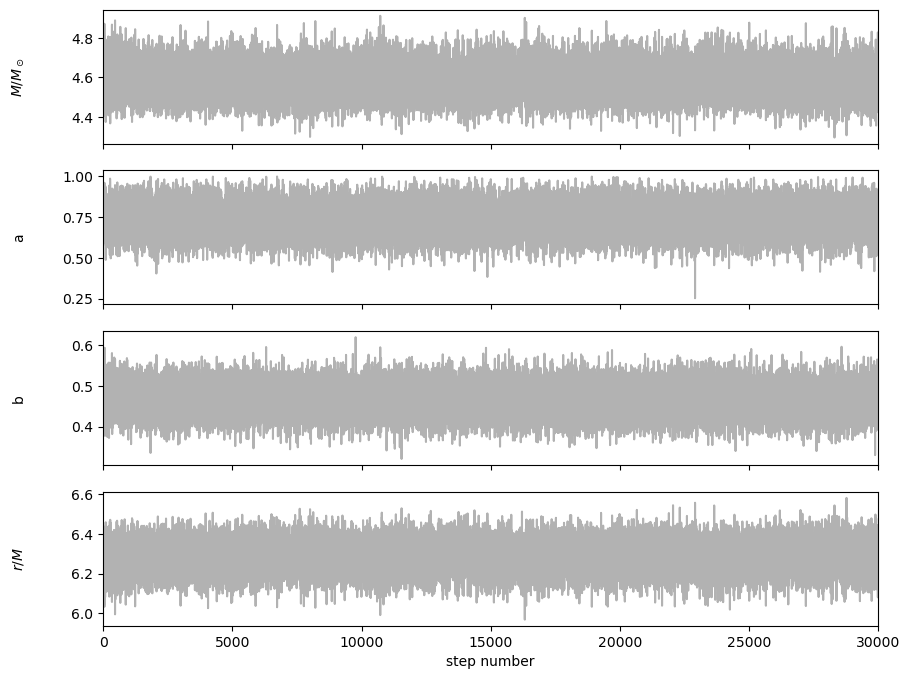

Removed no burn in


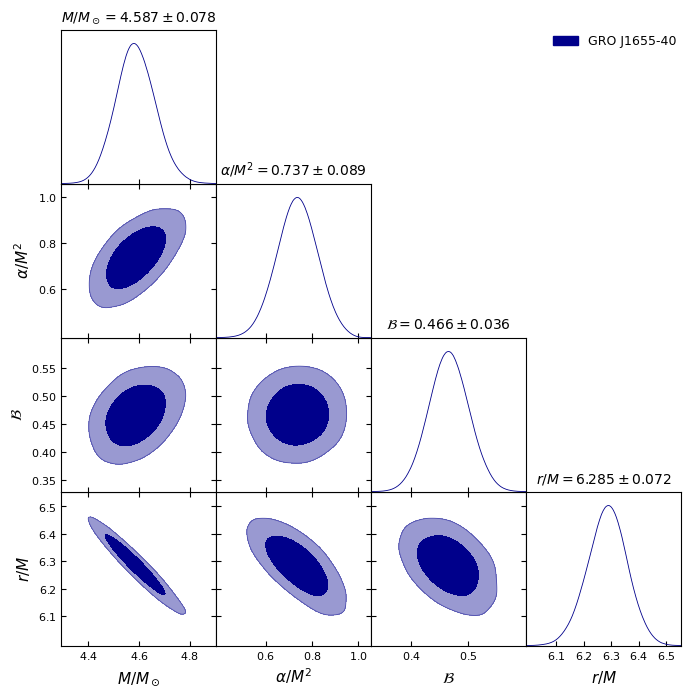

In [14]:

import numpy as np
import emcee
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# Xavfsiz ildiz olish funksiyasi
def mysqrt(x): 
    return np.sqrt(np.maximum(x, 0))

# Upper frequency funksiyasi (eslab qolingan ifoda asosida)
def Uppfreq(M, a, b, r):
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    aux1 = r**6
    freq = (16106.4 * mysqrt(aux0 / aux1)) / M
    return freq
# Xavfsiz ildiz olish funksiyasi
def mysqrt(x):
    return np.sqrt(np.maximum(x, 0))

# Full (Upper - Lower) Frequency function
def Lowfreq(M, a, b, r):
    # Upper qism (numerator/denominator)
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    term_upper = (16106.4 * mysqrt((r**-6) * aux0)) / M

    # Lower qism (numerator/denominator)
    aux1 = 8 * (r - 6) * r**6
    aux2 = a**2 * (2 + b * r)**2 * (24 + b * r * (13 + 2 * b * r))
    aux3 = 2 * a * r**3 * (36 + r * (16 + b * (40 + (6 + 9 * b) * r)))
    aux4 = aux1 - aux2 + aux3
    term_lower = (11388.9 * mysqrt((r**-10) * aux4)) / M

    output = term_upper - term_lower
    return output

# Data in the given format
data = {
    "upper": [441],
    "upper_err": [2],
    "lower": [298],
    "lower_err": [4]
}

# Extracting the data from the dictionary
nu_up_obs = np.array(data["upper"])
sigma_up_obs = np.array(data["upper_err"])
nu_low_obs = np.array(data["lower"])
sigma_low_obs = np.array(data["lower_err"])

# Theoretical functions
def nu_up_th(params):
    M, a, b, r = params
    return Uppfreq(M, a, b, r)

def nu_low_th(params):
    M, a, b, r = params
    return Lowfreq(M, a, b, r)

# Define the log likelihood function
def log_likelihood(params):
    M, a, b, r = params

    nu_up_th_values = nu_up_th(params)
    nu_low_th_values = nu_low_th(params)

    logL_up = -0.5 * np.sum(((nu_up_obs - nu_up_th_values) / sigma_up_obs) ** 2)
    logL_low = -0.5 * np.sum(((nu_low_obs - nu_low_th_values) / sigma_low_obs) ** 2)

    return logL_up + logL_low

# Prior parameters
Theta_0 = [5.4, 0.66, 0.45, 5.45]  # Example mean values for the priors
sigma_i = [0.3, 0.09, 0.035, 0.32]  # Example standard deviations for the priors
Theta_low = [4.0, 0., .0, 1.0]
Theta_high = [6.0, 1.0, 1.0, 10.0]


# Define the log prior function
def log_prior(params):
    M, a, b, r = params
    if not (Theta_low[0] < M < Theta_high[0] and Theta_low[1] < a < Theta_high[1] and Theta_low[2] < b < Theta_high[2] and Theta_low[3] < r < Theta_high[3]):
        return -np.inf  # Out of bounds

    logP_M = -0.5 * ((M - Theta_0[0]) / sigma_i[0]) ** 2
    logP_a = -0.5 * ((a - Theta_0[1]) / sigma_i[1]) ** 2
    logP_b = -0.5 * ((b - Theta_0[2]) / sigma_i[2]) ** 2
    logP_r = -0.5 * ((r - Theta_0[3]) / sigma_i[3]) ** 2

    return logP_M + logP_a + logP_b + logP_r

# Define the log posterior function
def log_posterior(params):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params)

# Set up the MCMC sampler
ndim = 4  # Number of parameters
nwalkers = 500  # Number of walkers
nsteps = 1000  # Number of steps

# Initial positions of the walkers
initial_pos = [Theta_0 + 1e-4 * np.random.randn(ndim) for i in range(nwalkers)]

# Create the sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

# Run the MCMC
sampler.run_mcmc(initial_pos, nsteps, progress=True)

# Get the samples
samples = sampler.get_chain(discard=100, thin=15, flat=True)

# Plot the results
fig, axes = plt.subplots(4, figsize=(10, 8), sharex=True)
labels = [r"$M/M_\odot$", r"a", r"b", r"$r/M$"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.show()

# Create a GetDist MCSamples instance
names = ["M", "a", "b", "r"]
labels = [r'M/M_\odot', r'\alpha/M^2', r'\mathcal{B}', r'r/M']
samples_getdist = MCSamples(samples=samples, names=names, labels=labels)

# Customized triangle plot
g = plots.get_subplot_plotter()
g.settings.figure_legend_frame = False
g.settings.alpha_filled_add = 0.4
g.settings.title_limit_fontsize = 13

# Define line styles
line_args = [{'ls': '-', 'color': 'darkblue'}, {'lw': 2, 'color': 'darkblue'}]

# Define contour colors
contour_colors = ['darkblue']

g.triangle_plot(
    [samples_getdist], 
    filled=True, 
    legend_labels=['GRO J1655-40'], 
    legend_loc='upper right', 
    line_args=line_args, 
    contour_colors=contour_colors,
    title_limit=1,  # first title limit (for 1D plots) is 68% by default
    markers={'l': 0}  # Example marker for l parameter at 0
)

plt.show()

g.export('RP-GRO J1655-40.pdf')

# GRS 1915+105

100%|███████████████████████████████████████| 1000/1000 [00:12<00:00, 80.30it/s]


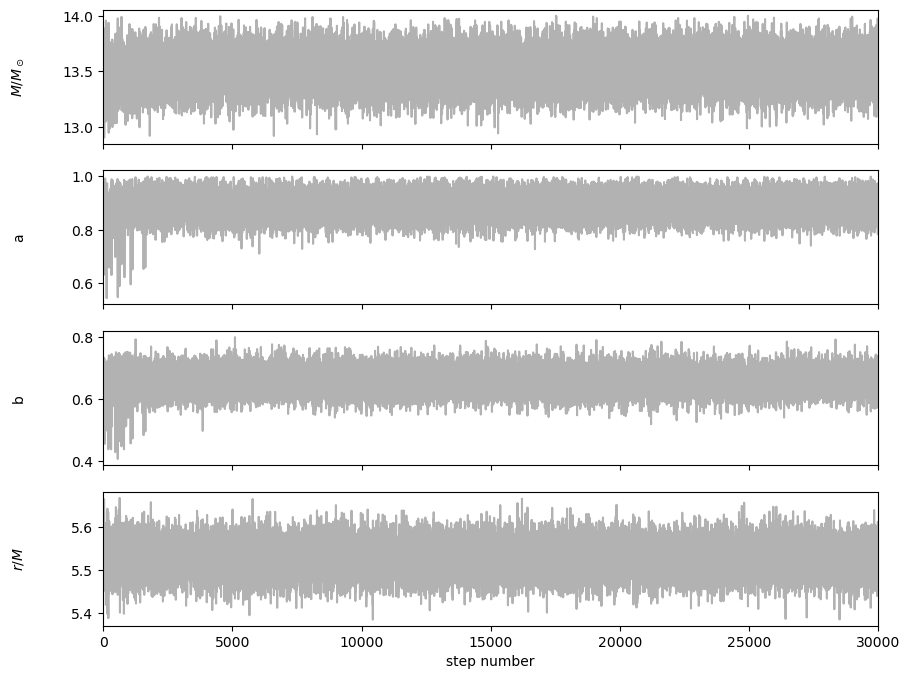

Removed no burn in


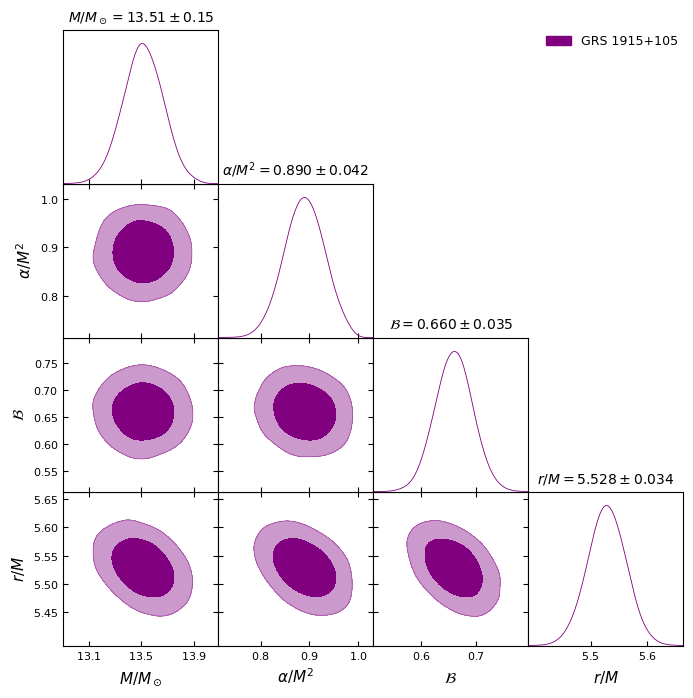

In [10]:

import numpy as np
import emcee
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# Xavfsiz ildiz olish funksiyasi
def mysqrt(x): 
    return np.sqrt(np.maximum(x, 0))

# Upper frequency funksiyasi (eslab qolingan ifoda asosida)
def Uppfreq(M, a, b, r):
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    aux1 = r**6
    freq = (16106.4 * mysqrt(aux0 / aux1)) / M
    return freq
# Xavfsiz ildiz olish funksiyasi
def mysqrt(x):
    return np.sqrt(np.maximum(x, 0))

# Full (Upper - Lower) Frequency function
def Lowfreq(M, a, b, r):
    # Upper qism (numerator/denominator)
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    term_upper = (16106.4 * mysqrt((r**-6) * aux0)) / M

    # Lower qism (numerator/denominator)
    aux1 = 8 * (r - 6) * r**6
    aux2 = a**2 * (2 + b * r)**2 * (24 + b * r * (13 + 2 * b * r))
    aux3 = 2 * a * r**3 * (36 + r * (16 + b * (40 + (6 + 9 * b) * r)))
    aux4 = aux1 - aux2 + aux3
    term_lower = (11388.9 * mysqrt((r**-10) * aux4)) / M

    output = term_upper - term_lower
    return output

# Data in the given format
data = {
    "upper": [168],
    "upper_err": [3],
    "lower": [113],
    "lower_err": [5]
}

# Extracting the data from the dictionary
nu_up_obs = np.array(data["upper"])
sigma_up_obs = np.array(data["upper_err"])
nu_low_obs = np.array(data["lower"])
sigma_low_obs = np.array(data["lower_err"])

# Theoretical functions
def nu_up_th(params):
    M, a, b, r = params
    return Uppfreq(M, a, b, r)

def nu_low_th(params):
    M, a, b, r = params
    return Lowfreq(M, a, b, r)

# Define the log likelihood function
def log_likelihood(params):
    M, a, b, r = params

    nu_up_th_values = nu_up_th(params)
    nu_low_th_values = nu_low_th(params)

    logL_up = -0.5 * np.sum(((nu_up_obs - nu_up_th_values) / sigma_up_obs) ** 2)
    logL_low = -0.5 * np.sum(((nu_low_obs - nu_low_th_values) / sigma_low_obs) ** 2)

    return logL_up + logL_low

# Prior parameters
Theta_0 = [12.4, 0.65, 0.45, 5.23]  # Example mean values for the priors
sigma_i = [0.2, 0.05, 0.04, 0.04]  # Example standard deviations for the priors
Theta_low = [8.0, 0., .0, 1.0]
Theta_high = [14.0, 1.0, 1.0, 10.0]

# Define the log prior function
def log_prior(params):
    M, a, b, r = params
    if not (Theta_low[0] < M < Theta_high[0] and Theta_low[1] < a < Theta_high[1] and Theta_low[2] < b < Theta_high[2] and Theta_low[3] < r < Theta_high[3]):
        return -np.inf  # Out of bounds

    logP_M = -0.5 * ((M - Theta_0[0]) / sigma_i[0]) ** 2
    logP_a = -0.5 * ((a - Theta_0[1]) / sigma_i[1]) ** 2
    logP_b = -0.5 * ((b - Theta_0[2]) / sigma_i[2]) ** 2
    logP_r = -0.5 * ((r - Theta_0[3]) / sigma_i[3]) ** 2

    return logP_M + logP_a + logP_b + logP_r

# Define the log posterior function
def log_posterior(params):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params)

# Set up the MCMC sampler
ndim = 4  # Number of parameters
nwalkers = 500  # Number of walkers
nsteps = 1000  # Number of steps

# Initial positions of the walkers
initial_pos = [Theta_0 + 1e-4 * np.random.randn(ndim) for i in range(nwalkers)]

# Create the sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

# Run the MCMC
sampler.run_mcmc(initial_pos, nsteps, progress=True)

# Get the samples
samples = sampler.get_chain(discard=100, thin=15, flat=True)

# Plot the results
fig, axes = plt.subplots(4, figsize=(10, 8), sharex=True)
labels = [r"$M/M_\odot$", r"a", r"b", r"$r/M$"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.show()

# Create a GetDist MCSamples instance
names = ["M", "a", "b", "r"]
labels = [r'M/M_\odot', r'\alpha/M^2', r'\mathcal{B}', r'r/M']
samples_getdist = MCSamples(samples=samples, names=names, labels=labels)

# Customized triangle plot
g = plots.get_subplot_plotter()
g.settings.figure_legend_frame = False
g.settings.alpha_filled_add = 0.4
g.settings.title_limit_fontsize = 13

# Define line styles
line_args = [{'ls': '-', 'color': 'purple'}, {'lw': 2, 'color': 'purple'}]

# Define contour colors
contour_colors = ['purple']

g.triangle_plot(
    [samples_getdist], 
    filled=True, 
    legend_labels=['GRS 1915+105'], 
    legend_loc='upper right', 
    line_args=line_args, 
    contour_colors=contour_colors,
    title_limit=1,  # first title limit (for 1D plots) is 68% by default
    markers={'l': 0}  # Example marker for l parameter at 0
)

plt.show()

g.export('RP-GRS 1915+105.pdf')

# H1743-332

100%|███████████████████████████████████████| 1000/1000 [00:12<00:00, 81.49it/s]


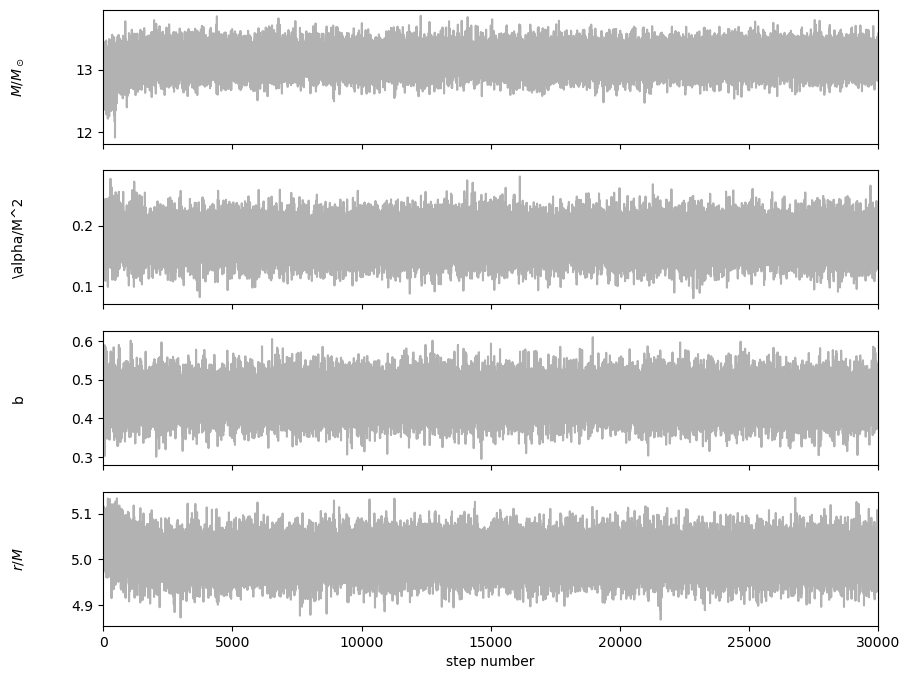

Removed no burn in


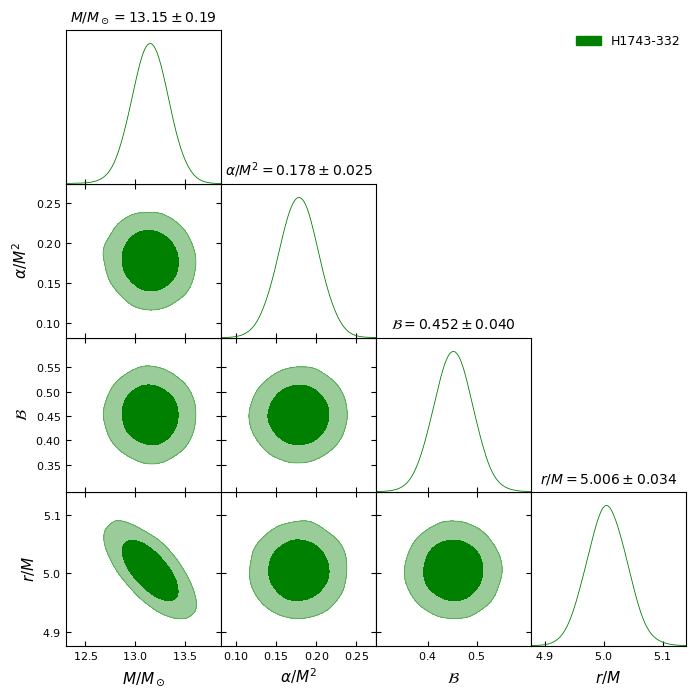

In [11]:

import numpy as np
import emcee
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# Xavfsiz ildiz olish funksiyasi
def mysqrt(x): 
    return np.sqrt(np.maximum(x, 0))

# Upper frequency funksiyasi (eslab qolingan ifoda asosida)
def Uppfreq(M, a, b, r):
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    aux1 = r**6
    freq = (16106.4 * mysqrt(aux0 / aux1)) / M
    return freq
# Xavfsiz ildiz olish funksiyasi
def mysqrt(x):
    return np.sqrt(np.maximum(x, 0))

# Full (Upper - Lower) Frequency function
def Lowfreq(M, a, b, r):
    # Upper qism (numerator/denominator)
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    term_upper = (16106.4 * mysqrt((r**-6) * aux0)) / M

    # Lower qism (numerator/denominator)
    aux1 = 8 * (r - 6) * r**6
    aux2 = a**2 * (2 + b * r)**2 * (24 + b * r * (13 + 2 * b * r))
    aux3 = 2 * a * r**3 * (36 + r * (16 + b * (40 + (6 + 9 * b) * r)))
    aux4 = aux1 - aux2 + aux3
    term_lower = (11388.9 * mysqrt((r**-10) * aux4)) / M

    output = term_upper - term_lower
    return output

# Data in the given format
data = {
    "upper": [240],
    "upper_err": [3],
    "lower": [165],
    "lower_err": [4]
}

# Extracting the data from the dictionary
nu_up_obs = np.array(data["upper"])
sigma_up_obs = np.array(data["upper_err"])
nu_low_obs = np.array(data["lower"])
sigma_low_obs = np.array(data["lower_err"])

# Theoretical functions
def nu_up_th(params):
    M, a, b, r = params
    return Uppfreq(M, a, b, r)

def nu_low_th(params):
    M, a, b, r = params
    return Lowfreq(M, a, b, r)

# Define the log likelihood function
def log_likelihood(params):
    M, a, b, r = params

    nu_up_th_values = nu_up_th(params)
    nu_low_th_values = nu_low_th(params)

    logL_up = -0.5 * np.sum(((nu_up_obs - nu_up_th_values) / sigma_up_obs) ** 2)
    logL_low = -0.5 * np.sum(((nu_low_obs - nu_low_th_values) / sigma_low_obs) ** 2)

    return logL_up + logL_low

# Prior parameters
Theta_0 = [9.79, 0.175, 0.45, 4.94]  # Example mean values for the priors
sigma_i = [0.5, 0.025, 0.04, 0.035]  # Example standard deviations for the priors
Theta_low = [8.0, 0., .0, 1.0]
Theta_high = [14.0, 1.0, 1.0, 10.0]

# Define the log prior function
def log_prior(params):
    M, a, b, r = params
    if not (Theta_low[0] < M < Theta_high[0] and Theta_low[1] < a < Theta_high[1] and Theta_low[2] < b < Theta_high[2] and Theta_low[3] < r < Theta_high[3]):
        return -np.inf  # Out of bounds

    logP_M = -0.5 * ((M - Theta_0[0]) / sigma_i[0]) ** 2
    logP_a = -0.5 * ((a - Theta_0[1]) / sigma_i[1]) ** 2
    logP_b = -0.5 * ((b - Theta_0[2]) / sigma_i[2]) ** 2
    logP_r = -0.5 * ((r - Theta_0[3]) / sigma_i[3]) ** 2

    return logP_M + logP_a + logP_b + logP_r

# Define the log posterior function
def log_posterior(params):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params)

# Set up the MCMC sampler
ndim = 4  # Number of parameters
nwalkers = 500  # Number of walkers
nsteps = 1000  # Number of steps

# Initial positions of the walkers
initial_pos = [Theta_0 + 1e-4 * np.random.randn(ndim) for i in range(nwalkers)]

# Create the sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

# Run the MCMC
sampler.run_mcmc(initial_pos, nsteps, progress=True)

# Get the samples
samples = sampler.get_chain(discard=100, thin=15, flat=True)

# Plot the results
fig, axes = plt.subplots(4, figsize=(10, 8), sharex=True)
labels = [r"$M/M_\odot$", r"\alpha/M^2", r"b", r"$r/M$"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.show()

# Create a GetDist MCSamples instance
names = ["M", "a", "b", "r"]
labels = [r'M/M_\odot', r'\alpha/M^2', r'\mathcal{B}', r'r/M']
samples_getdist = MCSamples(samples=samples, names=names, labels=labels)

# Customized triangle plot
g = plots.get_subplot_plotter()
g.settings.figure_legend_frame = False
g.settings.alpha_filled_add = 0.4
g.settings.title_limit_fontsize = 13

# Define line styles
line_args = [{'ls': '-', 'color': 'green'}, {'lw': 2, 'color': 'green'}]

# Define contour colors
contour_colors = ['green']

g.triangle_plot(
    [samples_getdist], 
    filled=True, 
    legend_labels=['H1743-332'], 
    legend_loc='upper right', 
    line_args=line_args, 
    contour_colors=contour_colors,
    title_limit=1,  # first title limit (for 1D plots) is 68% by default
    markers={'l': 0}  # Example marker for l parameter at 0
)

plt.show()

g.export('RP-H1743-332.pdf')

# XTE 1550-564

100%|███████████████████████████████████████| 1000/1000 [00:12<00:00, 82.65it/s]


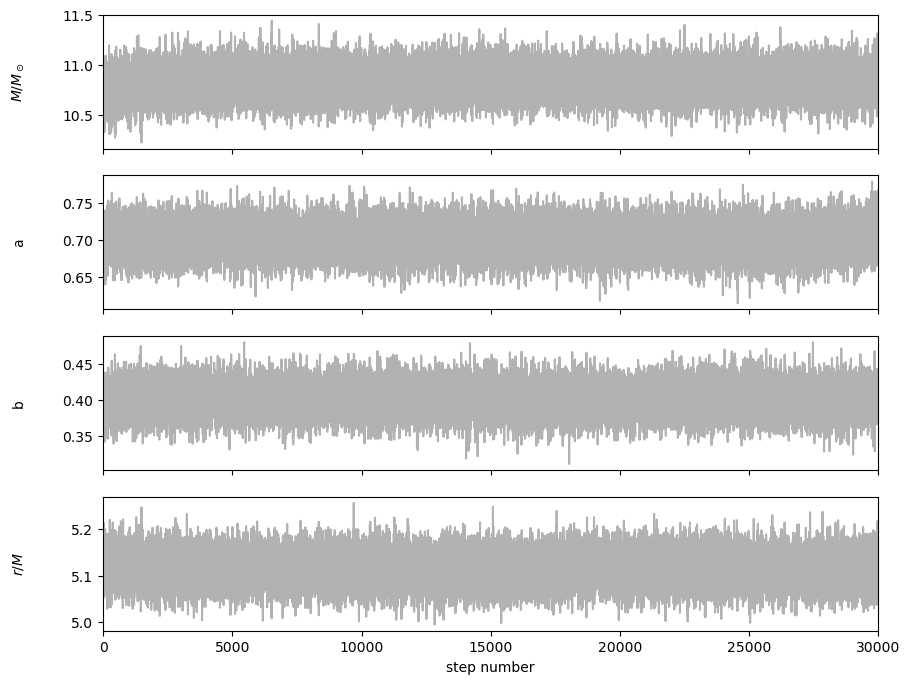

Removed no burn in


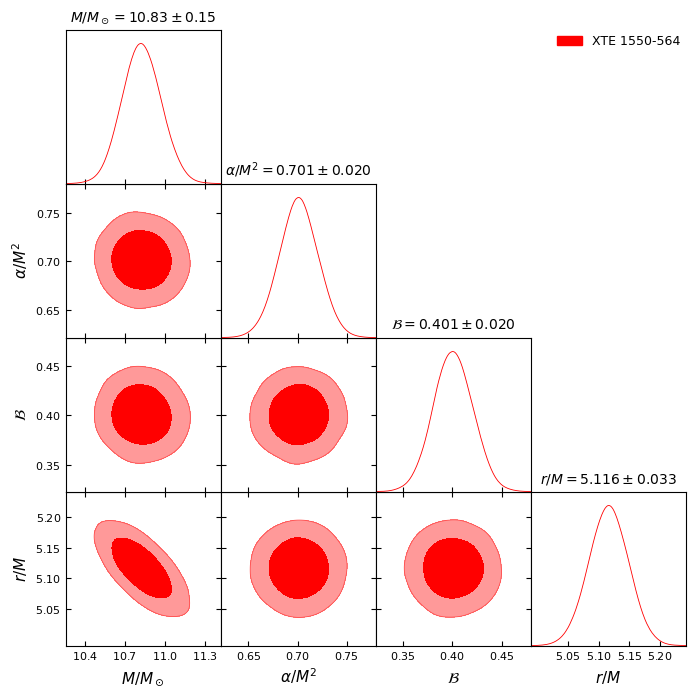

In [13]:

import numpy as np
import emcee
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# Xavfsiz ildiz olish funksiyasi
def mysqrt(x): 
    return np.sqrt(np.maximum(x, 0))

# Upper frequency funksiyasi (eslab qolingan ifoda asosida)
def Uppfreq(M, a, b, r):
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    aux1 = r**6
    freq = (16106.4 * mysqrt(aux0 / aux1)) / M
    return freq
# Xavfsiz ildiz olish funksiyasi
def mysqrt(x):
    return np.sqrt(np.maximum(x, 0))

# Full (Upper - Lower) Frequency function
def Lowfreq(M, a, b, r):
    # Upper qism (numerator/denominator)
    aux0 = 4 * r**3 - a * (2 + b * r) * (4 + b * r)
    term_upper = (16106.4 * mysqrt((r**-6) * aux0)) / M

    # Lower qism (numerator/denominator)
    aux1 = 8 * (r - 6) * r**6
    aux2 = a**2 * (2 + b * r)**2 * (24 + b * r * (13 + 2 * b * r))
    aux3 = 2 * a * r**3 * (36 + r * (16 + b * (40 + (6 + 9 * b) * r)))
    aux4 = aux1 - aux2 + aux3
    term_lower = (11388.9 * mysqrt((r**-10) * aux4)) / M

    output = term_upper - term_lower
    return output

# Data in the given format
data = {
    "upper": [276],
    "upper_err": [3],
    "lower": [184],
    "lower_err": [5]
}

# Extracting the data from the dictionary
nu_up_obs = np.array(data["upper"])
sigma_up_obs = np.array(data["upper_err"])
nu_low_obs = np.array(data["lower"])
sigma_low_obs = np.array(data["lower_err"])

# Theoretical functions
def nu_up_th(params):
    M, a, b, r = params
    return Uppfreq(M, a, b, r)

def nu_low_th(params):
    M, a, b, r = params
    return Lowfreq(M, a, b, r)

# Define the log likelihood function
def log_likelihood(params):
    M, a, b, r = params

    nu_up_th_values = nu_up_th(params)
    nu_low_th_values = nu_low_th(params)

    logL_up = -0.5 * np.sum(((nu_up_obs - nu_up_th_values) / sigma_up_obs) ** 2)
    logL_low = -0.5 * np.sum(((nu_low_obs - nu_low_th_values) / sigma_low_obs) ** 2)

    return logL_up + logL_low

# Prior parameters
Theta_0 = [9.1, 0.701, 0.4, 5.1]  # Example mean values for the priors
sigma_i = [0.61, 0.02, 0.02, 0.033]  # Example standard deviations for the priors
Theta_low = [6.0, 0., .0, 1.0]
Theta_high = [13.0, 1.0, 1.0, 10.0]


# Define the log prior function
def log_prior(params):
    M, a, b, r = params
    if not (Theta_low[0] < M < Theta_high[0] and Theta_low[1] < a < Theta_high[1] and Theta_low[2] < b < Theta_high[2] and Theta_low[3] < r < Theta_high[3]):
        return -np.inf  # Out of bounds

    logP_M = -0.5 * ((M - Theta_0[0]) / sigma_i[0]) ** 2
    logP_a = -0.5 * ((a - Theta_0[1]) / sigma_i[1]) ** 2
    logP_b = -0.5 * ((b - Theta_0[2]) / sigma_i[2]) ** 2
    logP_r = -0.5 * ((r - Theta_0[3]) / sigma_i[3]) ** 2

    return logP_M + logP_a + logP_b + logP_r

# Define the log posterior function
def log_posterior(params):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params)

# Set up the MCMC sampler
ndim = 4  # Number of parameters
nwalkers = 500  # Number of walkers
nsteps = 1000  # Number of steps

# Initial positions of the walkers
initial_pos = [Theta_0 + 1e-4 * np.random.randn(ndim) for i in range(nwalkers)]

# Create the sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

# Run the MCMC
sampler.run_mcmc(initial_pos, nsteps, progress=True)

# Get the samples
samples = sampler.get_chain(discard=100, thin=15, flat=True)

# Plot the results
fig, axes = plt.subplots(4, figsize=(10, 8), sharex=True)
labels = [r"$M/M_\odot$", r"a", r"b", r"$r/M$"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.show()

# Create a GetDist MCSamples instance
names = ["M", "a", "b", "r"]
labels = [r'M/M_\odot', r'\alpha/M^2', r'\mathcal{B}', r'r/M']
samples_getdist = MCSamples(samples=samples, names=names, labels=labels)

# Customized triangle plot
g = plots.get_subplot_plotter()
g.settings.figure_legend_frame = False
g.settings.alpha_filled_add = 0.4
g.settings.title_limit_fontsize = 13

# Define line styles
line_args = [{'ls': '-', 'color': 'red'}, {'lw': 2, 'color': 'red'}]

# Define contour colors
contour_colors = ['red']

g.triangle_plot(
    [samples_getdist], 
    filled=True, 
    legend_labels=['XTE 1550-564'], 
    legend_loc='upper right', 
    line_args=line_args, 
    contour_colors=contour_colors,
    title_limit=1,  # first title limit (for 1D plots) is 68% by default
    markers={'l': 0}  # Example marker for l parameter at 0
)

plt.show()

g.export('RP-XTE 1550-564.pdf')